In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# dataset load karane me help karega
from datasets import load_dataset

In [ ]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [ ]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [ ]:
label_names = emotion_dataset['train'].features['label'].names

In [ ]:
train_text

Column(['i didnt feel humiliated', 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake', 'im grabbing a minute to post i feel greedy wrong', 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property', 'i am feeling grouchy', ...])

In [ ]:
df_train = pd.DataFrame(
     {
         'text' : train_text,
         'label' : [label_names[i] for i in train_label]
     }
 )
df_test = pd.DataFrame(
     {
         'text' : test_text,
         'label' : [label_names[i] for i in test_label]
     }
 )

In [ ]:
df_train['label'].value_counts()

,count
label,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


In [ ]:
(df_train['label'].value_counts()/df_train.shape[0])*100

,count
label,
joy,33.51250
sadness,29.16250
anger,13.49375
fear,12.10625
love,8.15000
surprise,3.57500


In [ ]:
# num_words sets the maximum vocabulary size kept by the Keras Tokenizer based on word frequency. When you set num_words = N, the tokenizer keeps the top N - 1 most frequent words from the corpus and ignores rarer words during text-to-sequence conversion.

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
max_words = 10000
tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

In [ ]:
train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

In [ ]:
train_sequence

[[2, 139, 3, 679],
 [2,
  40,
  101,
  60,
  8,
  15,
  494,
  5,
  15,
  3496,
  553,
  32,
  60,
  61,
  128,
  148,
  76,
  1480,
  4,
  22,
  1255],
 [17, 3060, 7, 1149, 5, 286, 2, 3, 495, 438],
 [2, 24, 165, 8, 665, 27, 6, 4158, 2, 59, 47, 9, 13, 22, 72, 30, 6, 3497],
 [2, 24, 8, 1065],
 [73, 48, 8, 7, 56, 521, 319, 328, 158, 161, 9, 20],
 [73,
  48,
  329,
  35,
  7401,
  35,
  196,
  7402,
  888,
  4,
  73,
  2475,
  1384,
  7,
  159,
  1885,
  19,
  2,
  117,
  3,
  14,
  15,
  455],
 [2, 3, 29, 439, 27, 78, 29, 7, 1686, 35, 29, 760, 29, 7, 193, 267, 374],
 [2,
  21,
  48,
  25,
  5260,
  16,
  215,
  2,
  3,
  9,
  5260,
  99,
  5261,
  135,
  4,
  132,
  7,
  1038,
  4159],
 [2, 3, 666, 94],
 [2, 3, 14, 2, 21, 5, 80, 6, 733, 2, 93, 544, 304, 84],
 [2,
  39,
  3,
  9,
  483,
  22,
  7,
  530,
  440,
  4,
  9,
  2,
  40,
  920,
  5,
  21,
  69,
  840,
  10,
  1886,
  3061],
 [2, 70, 13, 90, 6, 5262, 52, 10, 193, 5, 3, 610],
 [2, 3, 339, 456, 2, 93, 32, 4160],
 [2,
  21,
  4161,

In [ ]:
padded_train_sequence = pad_sequences(train_sequence, maxlen=50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=50, padding='post', truncating='post')

In [ ]:
padded_train_sequence

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]],
      shape=(16000, 50), dtype=int32)

In [ ]:
train_labels = np.array(train_label)

In [ ]:
test_labels = np.array(test_label)

In [ ]:
num_classes = len(np.unique(train_labels))

In [ ]:
num_classes

6

In [ ]:
print(f'Vocabulary size : {len(tokenizer.word_index)}')
print(f'Max Sentence length : {padded_train_sequence.shape[1]}')

Vocabulary size : 15213
Max Sentence length : 50


In [ ]:
tokenizer.word_index

{'<unk>': 1,
 'i': 2,
 'feel': 3,
 'and': 4,
 'to': 5,
 'the': 6,
 'a': 7,
 'feeling': 8,
 'that': 9,
 'of': 10,
 'my': 11,
 'in': 12,
 'it': 13,
 'like': 14,
 'so': 15,
 'for': 16,
 'im': 17,
 'me': 18,
 'but': 19,
 'was': 20,
 'have': 21,
 'is': 22,
 'this': 23,
 'am': 24,
 'with': 25,
 'not': 26,
 'about': 27,
 'be': 28,
 'as': 29,
 'on': 30,
 'you': 31,
 'just': 32,
 'at': 33,
 'when': 34,
 'or': 35,
 'all': 36,
 'because': 37,
 'more': 38,
 'do': 39,
 'can': 40,
 'really': 41,
 'up': 42,
 't': 43,
 'are': 44,
 'by': 45,
 'very': 46,
 'know': 47,
 'been': 48,
 'if': 49,
 'out': 50,
 'myself': 51,
 'time': 52,
 'how': 53,
 'what': 54,
 'get': 55,
 'little': 56,
 'had': 57,
 'now': 58,
 'will': 59,
 'from': 60,
 'being': 61,
 'they': 62,
 'people': 63,
 'them': 64,
 'would': 65,
 'he': 66,
 'want': 67,
 'her': 68,
 'some': 69,
 'think': 70,
 'one': 71,
 'still': 72,
 'ive': 73,
 'him': 74,
 'even': 75,
 'who': 76,
 'an': 77,
 'life': 78,
 'its': 79,
 'make': 80,
 'there': 81,
 'we': 

In [ ]:
padded_train_sequence.shape

(16000, 50)

In [ ]:
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(train_labels),
    y = train_labels
)
class_weight_dict = dict(enumerate(class_weights))

In [35]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

In [46]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU, Bidirectional

In [38]:
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')

])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [39]:
lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [40]:
lstm_model.fit(
    padded_train_sequence, train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f'LSTM loss : {lstm_loss}')
print(f'LSTM Accuracy : {lstm_accuracy}')

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 73s 135ms/step - accuracy: 0.1548 - loss: 1.7947 - val_accuracy: 0.2755 - val_loss: 1.7903
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 135ms/step - accuracy: 0.1743 - loss: 1.7932 - val_accuracy: 0.2805 - val_loss: 1.7897
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 68s 137ms/step - accuracy: 0.1804 - loss: 1.7763 - val_accuracy: 0.1010 - val_loss: 1.8139
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 134ms/step - accuracy: 0.2755 - loss: 1.6245 - val_accuracy: 0.3990 - val_loss: 1.5503
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 134ms/step - accuracy: 0.4903 - loss: 1.2247 - val_accuracy: 0.4645 - val_loss: 1.2679
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 134ms/step - accuracy: 0.7122 - loss: 0.7662 - val_accuracy: 0.7615 - val_loss: 0.7113
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 131ms/step - accuracy: 0.8501 - loss: 0.4662 - val_accuracy: 0.8210 - val_loss: 0.5511
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 134ms/step - accuracy: 0.8931 - loss: 0

In [42]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [43]:
lstm_predictions = np.argmax(lstm_model.predict(padded_test_sequence), axis=1)

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step


<Axes: >

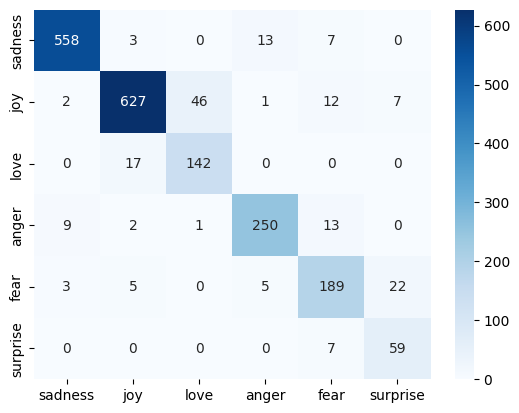

In [45]:
sns.heatmap(confusion_matrix(test_labels, lstm_predictions), annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)


In [48]:
bilstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),

    Bidirectional(LSTM(units=128, return_sequences=True)),
    Dropout(0.5),

    Bidirectional(LSTM(units=64)),
    Dropout(0.5),

    Dense(units=num_classes, activation='softmax')
])

bilstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

bilstm_model.fit(
    padded_train_sequence, train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

bilstm_loss, bilstm_accuracy = bilstm_model.evaluate(
    padded_test_sequence, test_labels
)

print(f'BiLSTM loss : {bilstm_loss}')
print(f'BiLSTM Accuracy : {bilstm_accuracy}')

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 201s 388ms/step - accuracy: 0.5603 - loss: 1.0593 - val_accuracy: 0.8820 - val_loss: 0.4171
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 197s 393ms/step - accuracy: 0.9064 - loss: 0.2920 - val_accuracy: 0.8945 - val_loss: 0.3235
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 197s 383ms/step - accuracy: 0.9345 - loss: 0.1843 - val_accuracy: 0.8980 - val_loss: 0.3574
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step - accuracy: 0.8820 - loss: 0.4171
BiLSTM loss : 0.4171101152896881
BiLSTM Accuracy : 0.8820000290870667


In [51]:
bilstm_predictions = np.argmax(bilstm_model.predict(padded_test_sequence), axis=1)

63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 188ms/step


<Axes: >

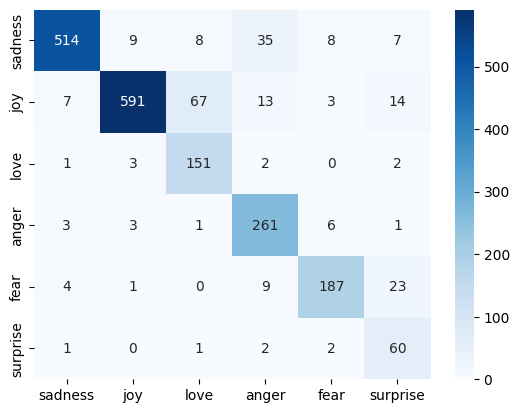

In [52]:
sns.heatmap(confusion_matrix(test_labels, bilstm_predictions), annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

In [53]:
bilstm_model2 = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),

    Bidirectional(LSTM(units=128, return_sequences=True)),
    Dropout(0.5),

    Bidirectional(LSTM(units=64)),
    Dropout(0.5),

    Dense(units=num_classes, activation='softmax')
])

bilstm_model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

bilstm_model2.fit(
    padded_train_sequence, train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

bilstm_loss2, bilstm_accuracy2 = bilstm_model2.evaluate(
    padded_test_sequence, test_labels
)

print(f'BiLSTM loss : {bilstm_loss2}')
print(f'BiLSTM Accuracy : {bilstm_accuracy2}')

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 156s 293ms/step - accuracy: 0.4950 - loss: 1.2245 - val_accuracy: 0.7760 - val_loss: 0.6947
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 145s 290ms/step - accuracy: 0.8976 - loss: 0.3289 - val_accuracy: 0.8860 - val_loss: 0.3754
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 143s 287ms/step - accuracy: 0.9197 - loss: 0.2304 - val_accuracy: 0.9050 - val_loss: 0.2777
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 143s 286ms/step - accuracy: 0.9399 - loss: 0.1628 - val_accuracy: 0.9080 - val_loss: 0.2417
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 145s 290ms/step - accuracy: 0.9519 - loss: 0.1283 - val_accuracy: 0.9055 - val_loss: 0.2720
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 143s 286ms/step - accuracy: 0.9636 - loss: 0.1098 - val_accuracy: 0.9100 - val_loss: 0.3119
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 202s 286ms/step - accuracy: 0.9595 - loss: 0.1138 - val_accuracy: 0.8995 - val_loss: 0.3222
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - accuracy: 0.9080 - loss: 0.2417 
BiLSTM loss 

In [54]:
bilstm_predictions2 = np.argmax(bilstm_model2.predict(padded_test_sequence), axis=1)

63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 197ms/step


<Axes: >

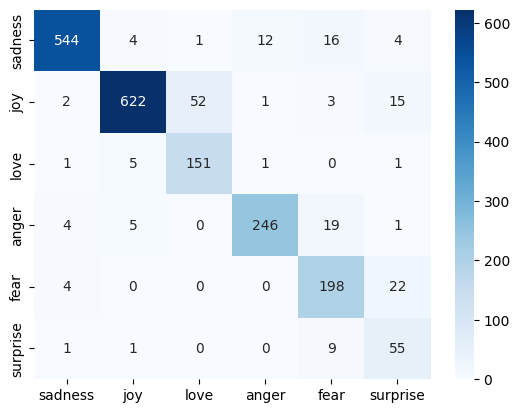

In [55]:
sns.heatmap(confusion_matrix(test_labels, bilstm_predictions2), annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

In [56]:
BiGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300, input_length=50),

    Bidirectional(GRU(units=128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [57]:
BiGRU.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [58]:
BiGRU.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [59]:
BiGRU.fit(
    padded_train_sequence, train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 208s 397ms/step - accuracy: 0.5769 - loss: 1.0341 - val_accuracy: 0.8865 - val_loss: 0.3491
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 160s 321ms/step - accuracy: 0.9235 - loss: 0.2185 - val_accuracy: 0.9170 - val_loss: 0.2247
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 160s 320ms/step - accuracy: 0.9488 - loss: 0.1364 - val_accuracy: 0.9185 - val_loss: 0.2571
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 200s 317ms/step - accuracy: 0.9623 - loss: 0.1037 - val_accuracy: 0.9250 - val_loss: 0.2379
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 204s 321ms/step - accuracy: 0.9727 - loss: 0.0729 - val_accuracy: 0.9275 - val_loss: 0.2509


In [60]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(
    padded_test_sequence, test_labels
)

print(f'BiGRU loss : {BiGRU_loss}')
print(f'BiGRU Accuracy : {BiGRU_accuracy}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step - accuracy: 0.9170 - loss: 0.2247
BiGRU loss : 0.22474820911884308
BiGRU Accuracy : 0.9169999957084656


In [61]:

import os
import json

# Create a folder for deployment artifacts
os.makedirs("emotion_model", exist_ok=True)

# 1. Save the complete trained model
BiGRU.save("emotion_model/bigru_model.keras")

# 2. Save the fitted tokenizer
with open("emotion_model/tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

# 3. Save the emotion labels in their correct order
with open("emotion_model/labels.json", "w", encoding="utf-8") as f:
    json.dump(label_names, f)

# 4. Save preprocessing configuration
config = {
    "max_words": 10000,
    "max_length": 50,
    "padding": "post",
    "truncating": "post",
    "oov_token": "<unk>"
}

with open("emotion_model/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)

print("All model artifacts saved successfully!")


All model artifacts saved successfully!
